## Step 1 - Imports and Settings

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project folder (works whether the notebook is in notebooks/ or the main folder)
BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
print("Project folder:", BASE)

# Find the CSV in raw_data, whatever its exact name
csv_files = list((BASE / "raw_data").glob("*.csv"))
print("CSV files found:", [f.name for f in csv_files])
RAW_FILE = csv_files[0]

CLEAN_FILE = BASE / "cleaned_data" / "life_expectancy_clean.csv"
IMAGES = BASE / "images"
IMAGES.mkdir(exist_ok=True)
CLEAN_FILE.parent.mkdir(exist_ok=True)

# One fixed colour per group, used in every chart
COLORS = {"Developed": "#2a78d6", "Developing": "#eb6834"}
plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", None)

Project folder: /Users/ylliajvazi/Desktop/Python projects/Life expectancy analysis
CSV files found: ['Life Expectancy Data.csv']


## Step 2 - Load the data

In [4]:
df_raw = pd.read_csv(RAW_FILE)
print("Rows, columns:", df_raw.shape)
df_raw.head()

Rows, columns: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## Step 3 - Inspect the data

In [5]:
# Column names and types (repr shows hidden spaces)
for col in df_raw.columns:
    print(repr(col), "->", df_raw[col].dtype)

'Country' -> str
'Year' -> int64
'Status' -> str
'Life expectancy ' -> float64
'Adult Mortality' -> float64
'infant deaths' -> int64
'Alcohol' -> float64
'percentage expenditure' -> float64
'Hepatitis B' -> float64
'Measles ' -> int64
' BMI ' -> float64
'under-five deaths ' -> int64
'Polio' -> float64
'Total expenditure' -> float64
'Diphtheria ' -> float64
' HIV/AIDS' -> float64
'GDP' -> float64
'Population' -> float64
' thinness  1-19 years' -> float64
' thinness 5-9 years' -> float64
'Income composition of resources' -> float64
'Schooling' -> float64


# Missing values
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(1)
missing_report = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_report = missing_report[missing_report["missing"] > 0].sort_values("missing", ascending=False)
print(missing_report)

In [7]:
# Duplicates and coverage
print("Duplicate rows:", df_raw.duplicated().sum())
print("Duplicate country-year pairs:", df_raw.duplicated(subset=["Country", "Year"]).sum())
print("Countries:", df_raw["Country"].nunique())
print("Years:", df_raw["Year"].min(), "to", df_raw["Year"].max())
print(df_raw["Status"].value_counts())

Duplicate rows: 0
Duplicate country-year pairs: 0
Countries: 193
Years: 2000 to 2015
Status
Developing    2426
Developed      512
Name: count, dtype: int64


In [8]:
# Summary statistics
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2007.52,4.61,2000.00,2004.00,2008.00,2012.00,2.015000e+03
Life expectancy,2928.0,69.22,9.52,36.30,63.10,72.10,75.70,8.900000e+01
Adult Mortality,2928.0,164.80,124.29,1.00,74.00,144.00,228.00,7.230000e+02
infant deaths,2938.0,30.30,117.93,0.00,0.00,3.00,22.00,1.800000e+03
Alcohol,2744.0,4.60,4.05,0.01,0.88,3.76,7.70,1.787000e+01
percentage expenditure,2938.0,738.25,1987.91,0.00,4.69,64.91,441.53,1.947991e+04
Hepatitis B,2385.0,80.94,25.07,1.00,77.00,92.00,97.00,9.900000e+01
Measles,2938.0,2419.59,11467.27,0.00,0.00,17.00,360.25,2.121830e+05
BMI,2904.0,38.32,20.04,1.00,19.30,43.50,56.20,8.730000e+01
under-five deaths,2938.0,42.04,160.45,0.00,0.00,4.00,28.00,2.500000e+03


## Step 4 - Clean the data

In [9]:
# 4.1 Tidy the column names
df = df_raw.copy()
df.columns = (df.columns
              .str.strip()
              .str.lower()
              .str.replace(r"[\s\-/]+", "_", regex=True))
df = df.rename(columns={
    "thinness_1_19_years": "thinness_10_19_years",
    "income_composition_of_resources": "income_composition",
    "percentage_expenditure": "health_spend_pct_gdp_per_capita",
    "total_expenditure": "health_spend_pct_govt",
})
print(df.columns.tolist())

['country', 'year', 'status', 'life_expectancy', 'adult_mortality', 'infant_deaths', 'alcohol', 'health_spend_pct_gdp_per_capita', 'hepatitis_b', 'measles', 'bmi', 'under_five_deaths', 'polio', 'health_spend_pct_govt', 'diphtheria', 'hiv_aids', 'gdp', 'population', 'thinness_10_19_years', 'thinness_5_9_years', 'income_composition', 'schooling']


In [10]:
# 4.2 Drop rows with no life expectancy, and unreliable columns
rows_before = len(df)
df = df.dropna(subset=["life_expectancy"])
print("Rows dropped:", rows_before - len(df))

df = df.drop(columns=["bmi", "population"])
print("Shape now:", df.shape)

Rows dropped: 10
Shape now: (2928, 20)


In [11]:
# 4.3 Mark impossible values as missing
print("Schooling = 0:", (df["schooling"] == 0).sum())
print("Income composition = 0:", (df["income_composition"] == 0).sum())
print("Adult mortality < 30:", (df["adult_mortality"] < 30).sum())

df.loc[df["schooling"] == 0, "schooling"] = np.nan
df.loc[df["income_composition"] == 0, "income_composition"] = np.nan
df.loc[df["adult_mortality"] < 30, "adult_mortality"] = np.nan

Schooling = 0: 26
Income composition = 0: 130
Adult mortality < 30: 410


In [12]:
# 4.4 Fill missing values
numeric_cols = df.select_dtypes("number").columns.drop("year")
df = df.sort_values(["country", "year"])
print("Missing before:", df[numeric_cols].isnull().sum().sum())

# Fill gaps from the same country's other years
df[numeric_cols] = (df.groupby("country")[numeric_cols]
                      .transform(lambda s: s.interpolate(limit_direction="both")))

# Anything still missing gets its group's median
df[numeric_cols] = (df.groupby("status")[numeric_cols]
                      .transform(lambda s: s.fillna(s.median())))
print("Missing after:", df[numeric_cols].isnull().sum().sum())

Missing before: 2403
Missing after: 0


In [13]:
# 4.5 Final check and save
df = df.reset_index(drop=True)
print("Final shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
df.to_csv(CLEAN_FILE, index=False)
print("Saved to", CLEAN_FILE)

Final shape: (2928, 20)
Duplicates: 0
Saved to /Users/ylliajvazi/Desktop/Python projects/Life expectancy analysis/cleaned_data/life_expectancy_clean.csv


## Step 5 - Analyze the data

In [14]:
# 5.1 Mean, median and spread
le = df["life_expectancy"]
print("Mean:  ", round(le.mean(), 2))
print("Median:", round(le.median(), 2))
print("Std:   ", round(le.std(), 2))
print("Min:   ", le.min())
print("Max:   ", le.max())

Mean:   69.22
Median: 72.1
Std:    9.52
Min:    36.3
Max:    89.0


In [15]:
# 5.2 Developed vs developing
print(df.groupby("status")["life_expectancy"].agg(["count", "mean", "median", "min", "max"]).round(2))

            count   mean  median   min   max
status                                      
Developed     512  79.20   79.25  69.9  89.0
Developing   2416  67.11   69.00  36.3  89.0


In [16]:
# 5.3 Trend over time
trend = df.groupby(["year", "status"])["life_expectancy"].mean().unstack()
trend["Gap"] = trend["Developed"] - trend["Developing"]
print(trend.round(2))
print("\nChange 2000 -> 2015:")
print((trend.loc[2015] - trend.loc[2000]).round(2))

status  Developed  Developing    Gap
year                                
2000        76.80       64.62  12.18
2001        77.13       65.01  12.12
2002        77.55       65.19  12.36
2003        77.94       65.21  12.73
2004        78.38       65.37  13.01
2005        78.59       66.01  12.58
2006        79.13       66.45  12.68
2007        79.30       66.86  12.44
2008        78.93       67.41  11.52
2009        79.58       67.89  11.69
2010        80.15       67.91  12.24
2011        80.71       68.52  12.18
2012        80.44       68.90  11.55
2013        80.68       69.23  11.45
2014        81.14       69.50  11.64
2015        80.71       69.69  11.02

Change 2000 -> 2015:
status
Developed     3.91
Developing    5.07
Gap          -1.16
dtype: float64


In [17]:
# 5.4 Top and bottom countries in 2015
latest = df[df["year"] == 2015]
print("Top 10 in 2015:")
print(latest.nlargest(10, "life_expectancy")[["country", "status", "life_expectancy"]])
print("\nBottom 10 in 2015:")
print(latest.nsmallest(10, "life_expectancy")[["country", "status", "life_expectancy"]])

Top 10 in 2015:
          country      status  life_expectancy
2351     Slovenia   Developed             88.0
751       Denmark   Developed             86.0
543         Chile  Developing             85.0
671        Cyprus   Developed             85.0
1327        Japan   Developed             83.7
2527  Switzerland   Developed             83.4
2319    Singapore   Developed             83.1
127     Australia   Developed             82.8
2431        Spain   Developed             82.8
1183      Iceland   Developed             82.7

Bottom 10 in 2015:
                       country      status  life_expectancy
2303              Sierra Leone  Developing             51.0
63                      Angola  Developing             52.4
511   Central African Republic  Developing             52.5
527                       Chad  Developing             53.1
703              Côte d'Ivoire  Developing             53.3
1487                   Lesotho  Developing             53.7
1903                   Nige

In [18]:
# 5.5 Biggest improvers, 2000 -> 2015
pivot = df.pivot_table(index="country", columns="year", values="life_expectancy")
gains = (pivot[2015] - pivot[2000]).dropna().sort_values(ascending=False)
print(gains.head(10).round(1))

country
Zimbabwe                            21.0
Eritrea                             19.4
Zambia                              18.0
Botswana                            17.9
Rwanda                              17.8
Uganda                              15.7
Malawi                              15.2
Bolivia (Plurinational State of)    14.4
Ethiopia                            13.6
United Republic of Tanzania         12.6
dtype: float64


In [19]:
# 5.6 Correlation of each indicator with life expectancy
corr = df[numeric_cols].corr()["life_expectancy"].drop("life_expectancy").sort_values()
print(corr.round(2))

adult_mortality                   -0.76
hiv_aids                          -0.56
thinness_10_19_years              -0.47
thinness_5_9_years                -0.47
under_five_deaths                 -0.22
infant_deaths                     -0.20
measles                           -0.16
health_spend_pct_govt              0.23
hepatitis_b                        0.34
health_spend_pct_gdp_per_capita    0.38
alcohol                            0.40
gdp                                0.45
polio                              0.46
diphtheria                         0.47
schooling                          0.77
income_composition                 0.86
Name: life_expectancy, dtype: float64


## Step 6 - Visualization

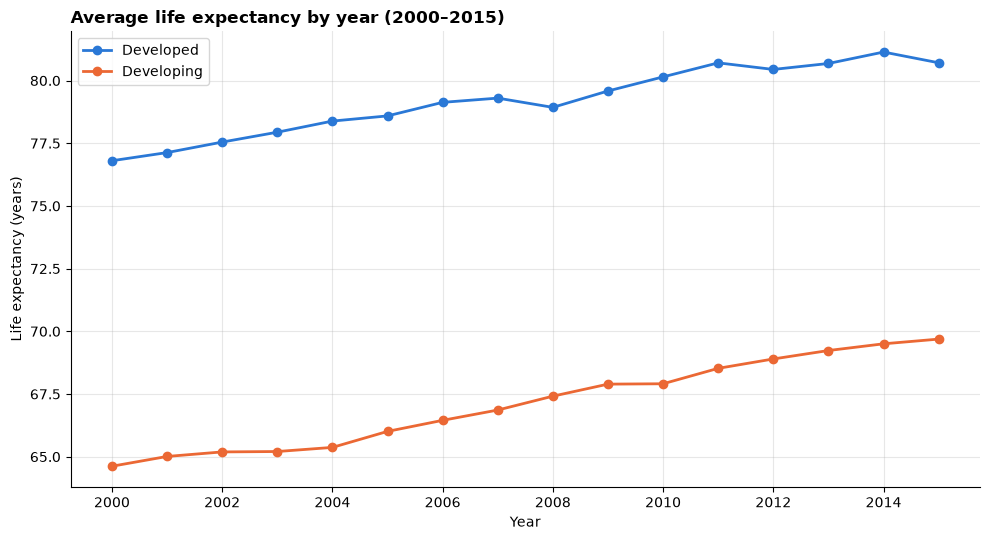

In [20]:
# Chart 1: Trend line
fig, ax = plt.subplots()
for group in ["Developed", "Developing"]:
    ax.plot(trend.index, trend[group], marker="o", linewidth=2,
            color=COLORS[group], label=group)
ax.set_title("Average life expectancy by year (2000–2015)", loc="left", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Life expectancy (years)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "01_trend_by_status.png", dpi=150)
plt.show()

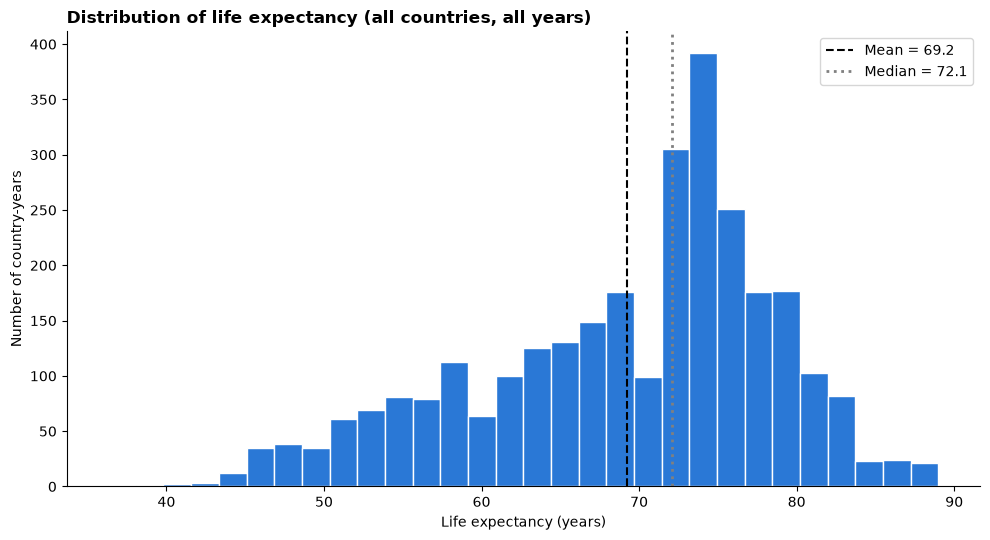

In [21]:
# Chart 2: Histogram
fig, ax = plt.subplots()
ax.hist(le, bins=30, color="#2a78d6", edgecolor="white")
ax.axvline(le.mean(), color="black", linestyle="--", label=f"Mean = {le.mean():.1f}")
ax.axvline(le.median(), color="grey", linestyle=":", linewidth=2, label=f"Median = {le.median():.1f}")
ax.set_title("Distribution of life expectancy (all countries, all years)", loc="left", fontweight="bold")
ax.set_xlabel("Life expectancy (years)")
ax.set_ylabel("Number of country-years")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "02_distribution.png", dpi=150)
plt.show()

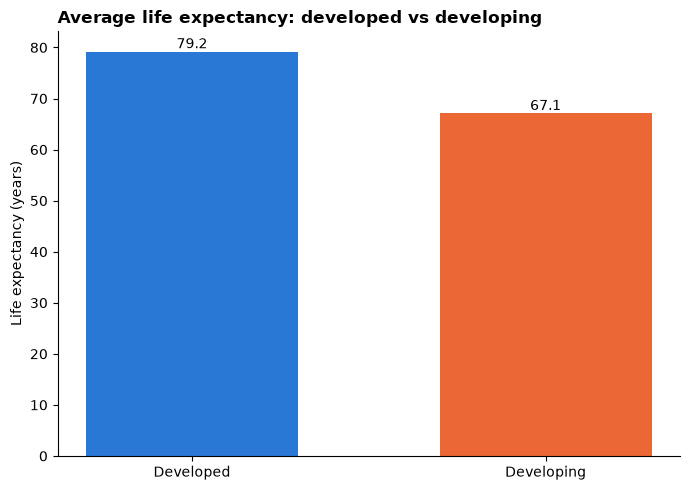

In [22]:
# Chart 3: Bar chart, developed vs developing
avg_by_status = df.groupby("status")["life_expectancy"].mean()
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(avg_by_status.index, avg_by_status.values,
              color=[COLORS[s] for s in avg_by_status.index], width=0.6)
ax.bar_label(bars, fmt="%.1f")
ax.set_title("Average life expectancy: developed vs developing", loc="left", fontweight="bold")
ax.set_ylabel("Life expectancy (years)")
plt.tight_layout()
plt.savefig(IMAGES / "03_status_bar.png", dpi=150)
plt.show()

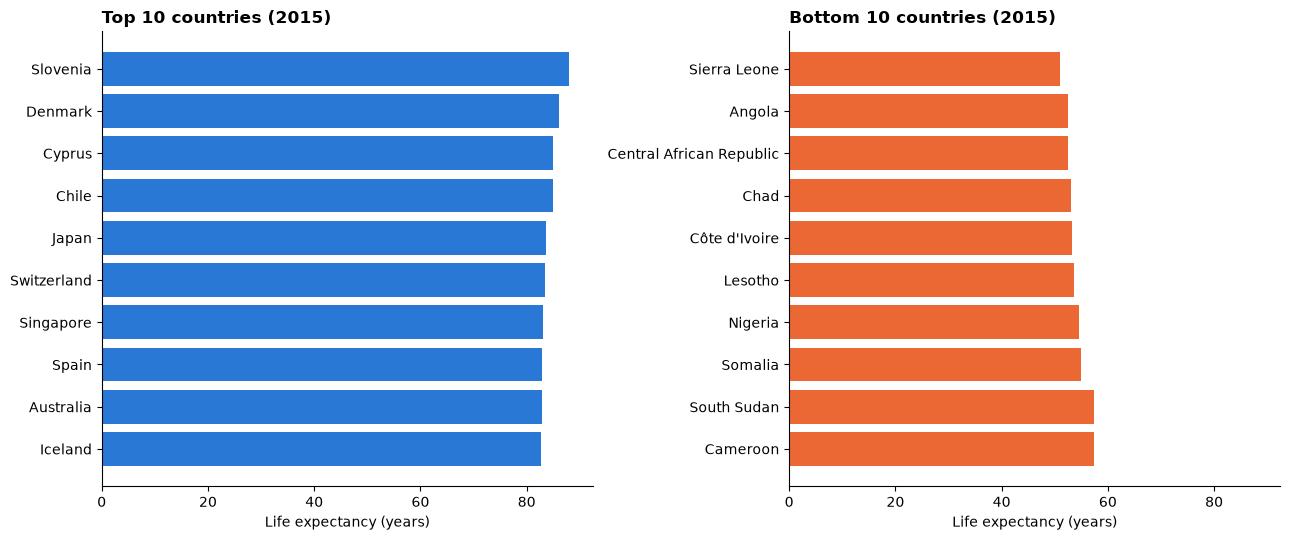

In [23]:
# Chart 4: Top and bottom 10 countries
top10 = latest.nlargest(10, "life_expectancy").sort_values("life_expectancy")
bottom10 = latest.nsmallest(10, "life_expectancy").sort_values("life_expectancy", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True)
ax1.barh(top10["country"], top10["life_expectancy"], color="#2a78d6")
ax1.set_title("Top 10 countries (2015)", loc="left", fontweight="bold")
ax2.barh(bottom10["country"], bottom10["life_expectancy"], color="#eb6834")
ax2.set_title("Bottom 10 countries (2015)", loc="left", fontweight="bold")
for ax in (ax1, ax2):
    ax.set_xlabel("Life expectancy (years)")
plt.tight_layout()
plt.savefig(IMAGES / "04_top_bottom_2015.png", dpi=150)
plt.show()

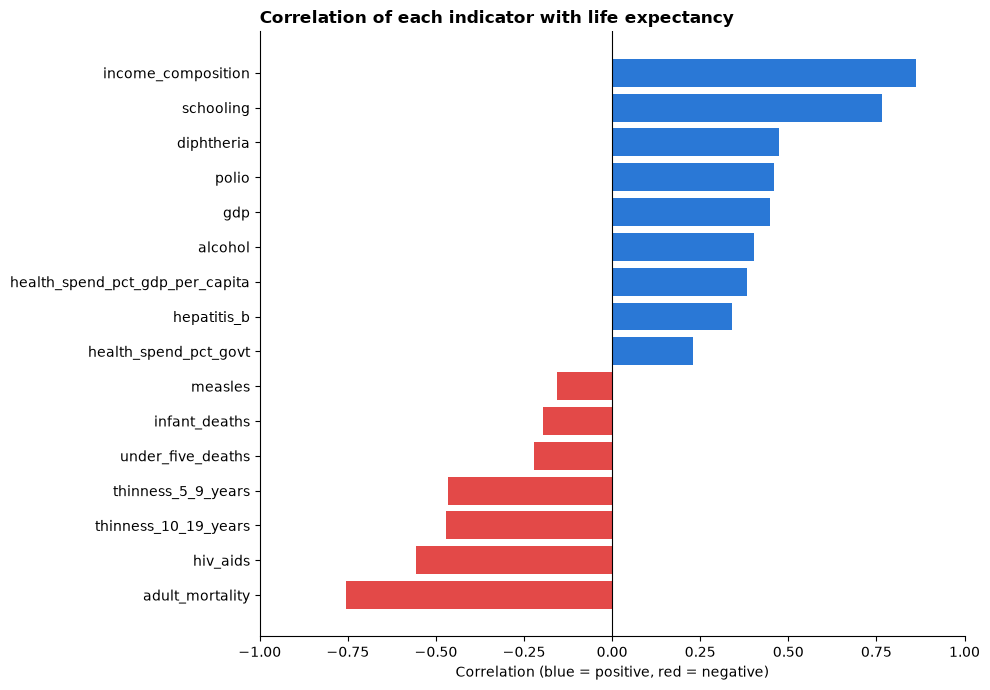

In [24]:
# Chart 5: Correlation bars
fig, ax = plt.subplots(figsize=(10, 7))
colors = ["#2a78d6" if v > 0 else "#e34948" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_title("Correlation of each indicator with life expectancy", loc="left", fontweight="bold")
ax.set_xlabel("Correlation (blue = positive, red = negative)")
plt.tight_layout()
plt.savefig(IMAGES / "05_correlations.png", dpi=150)
plt.show()

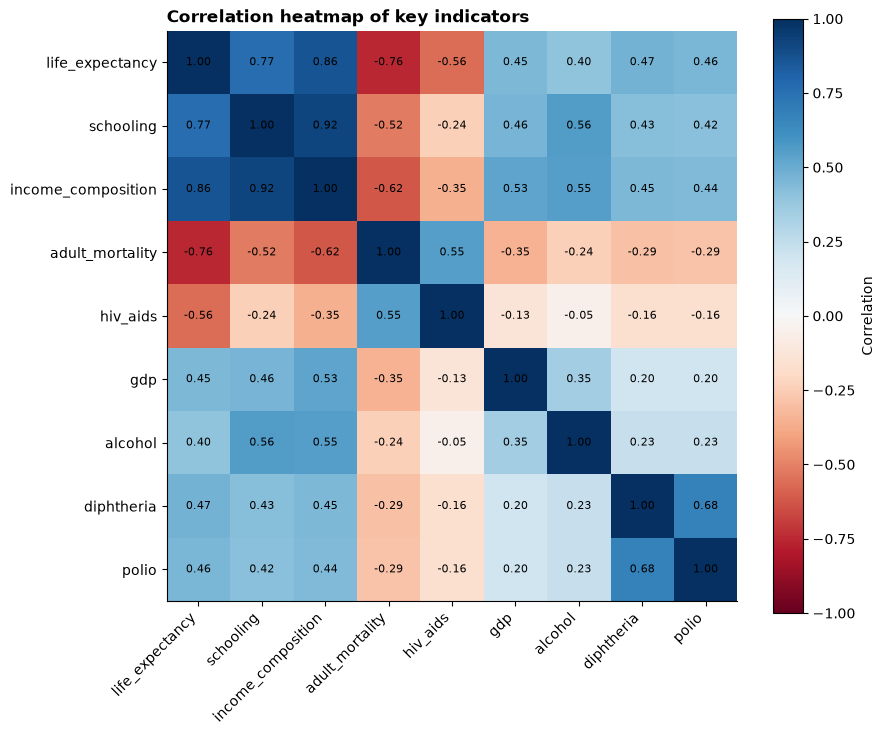

In [25]:
# Chart 6: Correlation heatmap
key_cols = ["life_expectancy", "schooling", "income_composition", "adult_mortality",
            "hiv_aids", "gdp", "alcohol", "diphtheria", "polio"]
matrix = df[key_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(matrix, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(key_cols)))
ax.set_xticklabels(key_cols, rotation=45, ha="right")
ax.set_yticks(range(len(key_cols)))
ax.set_yticklabels(key_cols)
for i in range(len(key_cols)):
    for j in range(len(key_cols)):
        ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation heatmap of key indicators", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(IMAGES / "06_heatmap.png", dpi=150)
plt.show()

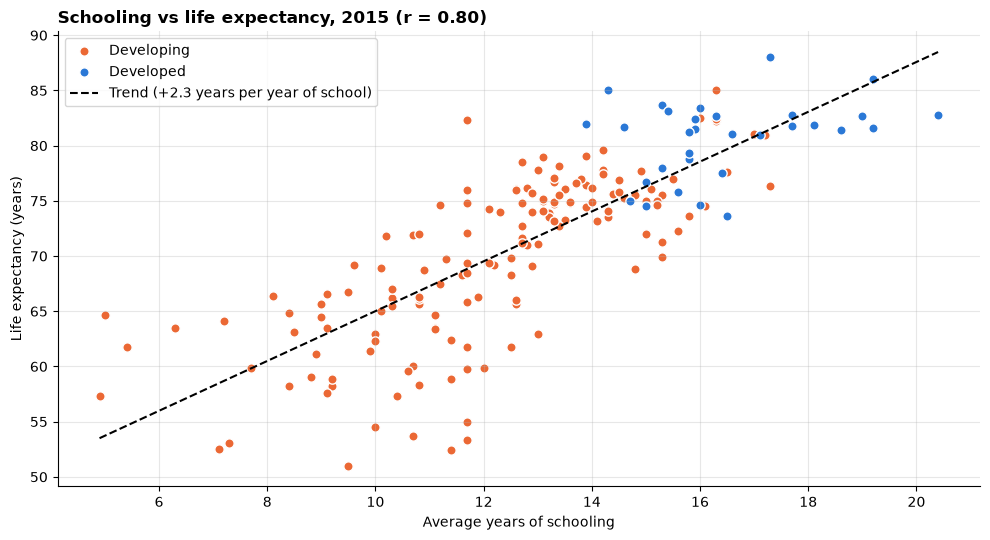

In [26]:
# Chart 7: Scatter plot, schooling vs life expectancy
fig, ax = plt.subplots()
for group in ["Developing", "Developed"]:
    d = latest[latest["status"] == group]
    ax.scatter(d["schooling"], d["life_expectancy"], color=COLORS[group],
               edgecolor="white", s=45, label=group)

m, b = np.polyfit(latest["schooling"], latest["life_expectancy"], 1)
xs = np.linspace(latest["schooling"].min(), latest["schooling"].max(), 100)
ax.plot(xs, m * xs + b, color="black", linestyle="--", label=f"Trend (+{m:.1f} years per year of school)")

r = latest["schooling"].corr(latest["life_expectancy"])
ax.set_title(f"Schooling vs life expectancy, 2015 (r = {r:.2f})", loc="left", fontweight="bold")
ax.set_xlabel("Average years of schooling")
ax.set_ylabel("Life expectancy (years)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "07_schooling_scatter.png", dpi=150)
plt.show()

## Step 7 - Key Insights

1. **The average is pulled down by a group of low-scoring countries.** Mean life expectancy is **69.2 years**, but the median is **72.1**. Most countries sit between 70 and 80 years (see the histogram), but a long tail of countries with very low values, down to 36 years, pulls the mean below the median.

2. **There is a 12-year gap between developed and developing countries.** Developed countries average **79.2 years** and developing countries **67.1 years**.

3. **Life expectancy rose in both groups, and the gap narrowed slightly.** Between 2000 and 2015, developing countries gained **5.1 years** and developed countries **3.9 years**. The gap fell from **12.2 to 11.0 years**.

4. **The gap between countries is still very large.** In 2015 the top 10 countries (mostly developed, such as Japan, Switzerland and Spain) were all above 82 years. The bottom 10, all in sub-Saharan Africa, ranged from **51 years (Sierra Leone)** to 57 years. That is a difference of more than 30 years.

5. **Education and income have the strongest positive links to life expectancy.** Income composition (r = +0.86) and schooling (r = +0.77) have the highest correlations. In 2015, each extra year of schooling went with about **2.3 more years** of life expectancy (r = 0.80). GDP alone has a weaker link (r = +0.45).

6. **Adult mortality and HIV/AIDS have the strongest negative links** (r = −0.76 and −0.56). Vaccination rates (diphtheria, polio) have moderate positive links (about +0.46).

7. **Correlation does not prove causation.** Schooling and income are closely linked to each other (r = 0.92), so this data alone cannot show which factor actually causes longer lives.

**Limitations:** the raw data had quality problems. I dropped the BMI and population columns, replaced impossible values (such as 0 years of schooling) and filled 2,403 missing values. Some values still look too high. For example, Slovenia's 88.0 years in 2015 is above official estimates. Individual country figures should therefore be treated with caution, but the overall patterns are consistent.